# Project: Bankruptcy Prevention

#### Business Objective:

This is a classification project, since the variable to predict is binary (bankruptcy or non-bankruptcy). The goal here is to model the probability that a business goes bankrupt from different features.

The data file contains 7 features about 250 companies.

The data set includes the following variables:

1. industrial_risk: 0=low risk, 0.5=medium risk, 1=high risk.

2. management_risk: 0=low risk, 0.5=medium risk, 1=high risk.

3. financial flexibility: 0=low flexibility, 0.5=medium flexibility, 1=high flexibility

4. credibility: 0=low credibility, 0.5=medium credibility, 1=high credibility.

5. competitiveness: 0=low competitiveness, 0.5=medium competitiveness, 1=high competitiveness.

6. operating_risk: 0=low risk, 0.5=medium risk, 1=high risk.

7. class: bankruptcy, non-bankruptcy (target variable).


## Part1 - Data set Details & EDA

In [50]:
import numpy as np   
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
import xgboost as xgb
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.metrics import roc_curve, auc

In [51]:
df=pd.read_csv(r"C:\Users\rasik\Downloads\Bankruptcy_prevention.csv")
df.head()

,industrial_risk,management_risk,financial_flexibility,credibility,competitiveness,operating_risk,class
0,0.5,1.0,0.0,0.0,0.0,0.5,bankruptcy
1,0.0,1.0,0.0,0.0,0.0,1.0,bankruptcy
2,1.0,0.0,0.0,0.0,0.0,1.0,bankruptcy
3,0.5,0.0,0.0,0.5,0.0,1.0,bankruptcy
4,1.0,1.0,0.0,0.0,0.0,1.0,bankruptcy


In [52]:
df.tail()

,industrial_risk,management_risk,financial_flexibility,credibility,competitiveness,operating_risk,class
245,0.0,1.0,1.0,1.0,1.0,1.0,non-bankruptcy
246,1.0,1.0,0.5,1.0,1.0,0.0,non-bankruptcy
247,0.0,1.0,1.0,0.5,0.5,0.0,non-bankruptcy
248,1.0,0.0,0.5,1.0,0.5,0.0,non-bankruptcy
249,1.0,0.0,0.5,0.5,1.0,1.0,non-bankruptcy


In [53]:
df.shape

(250, 7)

In [54]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 250 entries, 0 to 249
Data columns (total 7 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   industrial_risk        250 non-null    float64
 1   management_risk        250 non-null    float64
 2   financial_flexibility  250 non-null    float64
 3   credibility            250 non-null    float64
 4   competitiveness        250 non-null    float64
 5   operating_risk         250 non-null    float64
 6   class                  250 non-null    object 
dtypes: float64(6), object(1)
memory usage: 13.8+ KB


In [55]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
industrial_risk,250.0,0.518,0.411526,0.0,0.0,0.5,1.0,1.0
management_risk,250.0,0.614,0.410705,0.0,0.5,0.5,1.0,1.0
financial_flexibility,250.0,0.376,0.401583,0.0,0.0,0.5,0.5,1.0
credibility,250.0,0.470,0.415682,0.0,0.0,0.5,1.0,1.0
competitiveness,250.0,0.476,0.440682,0.0,0.0,0.5,1.0,1.0
operating_risk,250.0,0.570,0.434575,0.0,0.0,0.5,1.0,1.0


In [56]:
df.isnull().sum()

industrial_risk          0
management_risk          0
financial_flexibility    0
credibility              0
competitiveness          0
operating_risk           0
class                    0
dtype: int64

In [57]:
df.duplicated().sum()

np.int64(147)

* The dataset contains 250 rows and 7 columns.
* There are 6 predictor variables and 1 target variable (class).
* All predictor variables are in float format.
* The six predictors have three possible values: 0, 0.5, and 1, representing low, medium, and high risk respectively.
* The target variable class is categorical with two classes: bankruptcy and non-bankruptcy.
* No missing values are present in the dataset.

In [58]:
dups = df.duplicated()
print('Number of duplicate rows = %d' % (dups.sum()))

df[dups]

Number of duplicate rows = 147


,industrial_risk,management_risk,financial_flexibility,credibility,competitiveness,operating_risk,class
11,0.0,1.0,0.0,0.0,0.0,1.0,bankruptcy
13,1.0,1.0,0.0,0.0,0.0,1.0,bankruptcy
15,0.5,1.0,0.0,0.0,0.0,0.5,bankruptcy
16,0.5,1.0,0.0,0.0,0.0,0.5,bankruptcy
18,0.5,1.0,0.0,0.0,0.0,1.0,bankruptcy
...,...,...,...,...,...,...,...
245,0.0,1.0,1.0,1.0,1.0,1.0,non-bankruptcy
246,1.0,1.0,0.5,1.0,1.0,0.0,non-bankruptcy
247,0.0,1.0,1.0,0.5,0.5,0.0,non-bankruptcy
248,1.0,0.0,0.5,1.0,0.5,0.0,non-bankruptcy


In [59]:
df = df.drop_duplicates().reset_index(drop=True)

In [60]:
df["class"].value_counts()

class
non-bankruptcy    78
bankruptcy        25
Name: count, dtype: int64

In [61]:
df.shape

(103, 7)

* 147 duplicate rows were identified,removed duplicates for obtaining a better model.
* Remaining data contains 103 rows and 7 columns.

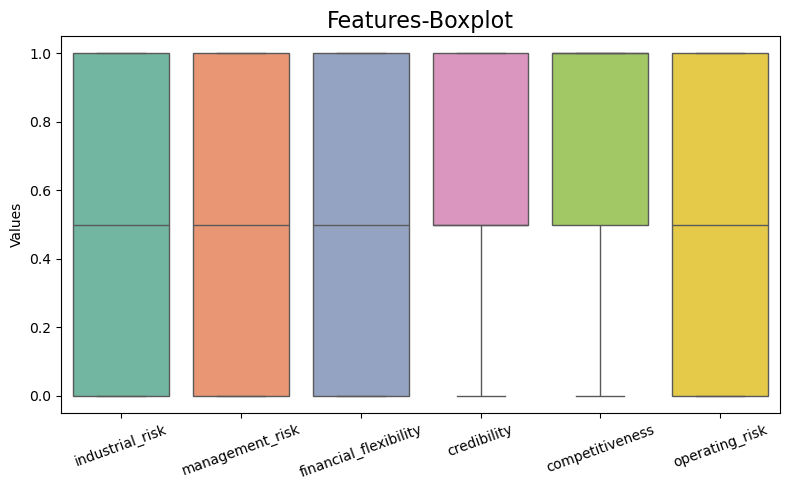

In [62]:
plt.figure(figsize=(8,5)) 
sns.boxplot(data=df, palette="Set2")
plt.title("Features-Boxplot",fontsize=16)
plt.ylabel("Values")
plt.grid(False)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

* Industrial risk and operating risk show values ranging from 0 to 1, with medians around 0.5, while credibility and competitiveness are concentrated toward higher values.
* Management risk is concentrated between 0.5 and 1, indicating that many companies have medium to high management risk, which may be associated with increased bankruptcy risk.
* Financial flexibility is relatively balanced across the values 0, 0.5, and 1, indicating varying levels of financial flexibility among companies.

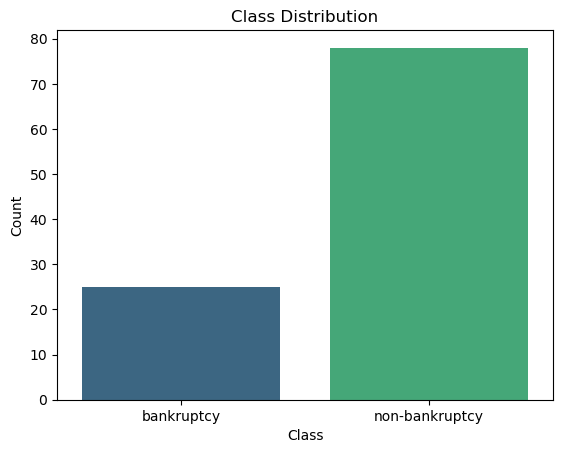

In [63]:
sns.countplot(x="class", data=df, palette="viridis")
plt.title("Class Distribution")
plt.xlabel("Class")
plt.ylabel("Count")
plt.show()

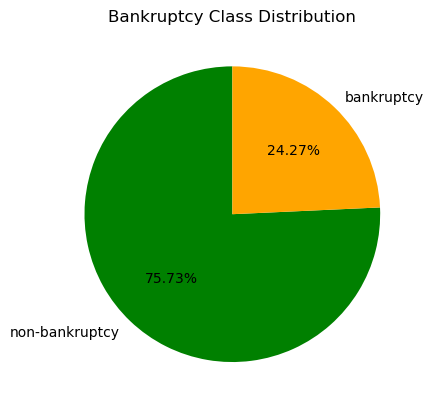

In [64]:
df["class"].value_counts().plot(kind="pie",autopct="%1.2f%%",colors=["green", "orange"],startangle=90)
plt.title("Bankruptcy Class Distribution")
plt.ylabel("")
plt.show()

* The dataset contains more non-bankruptcy cases (75.6%) than bankruptcy cases (24.3%).
* The two classes show a noticeable difference in their sample counts, indicating a class imbalance in the dataset.
* Both classes have sufficient representation for developing a binary classification model.

In [65]:
df.columns

Index(['industrial_risk', 'management_risk', 'financial_flexibility',
       'credibility', 'competitiveness', 'operating_risk', 'class'],
      dtype='object')

In [66]:
features=['industrial_risk', 'management_risk', 'financial_flexibility',
       'credibility', 'competitiveness', 'operating_risk']

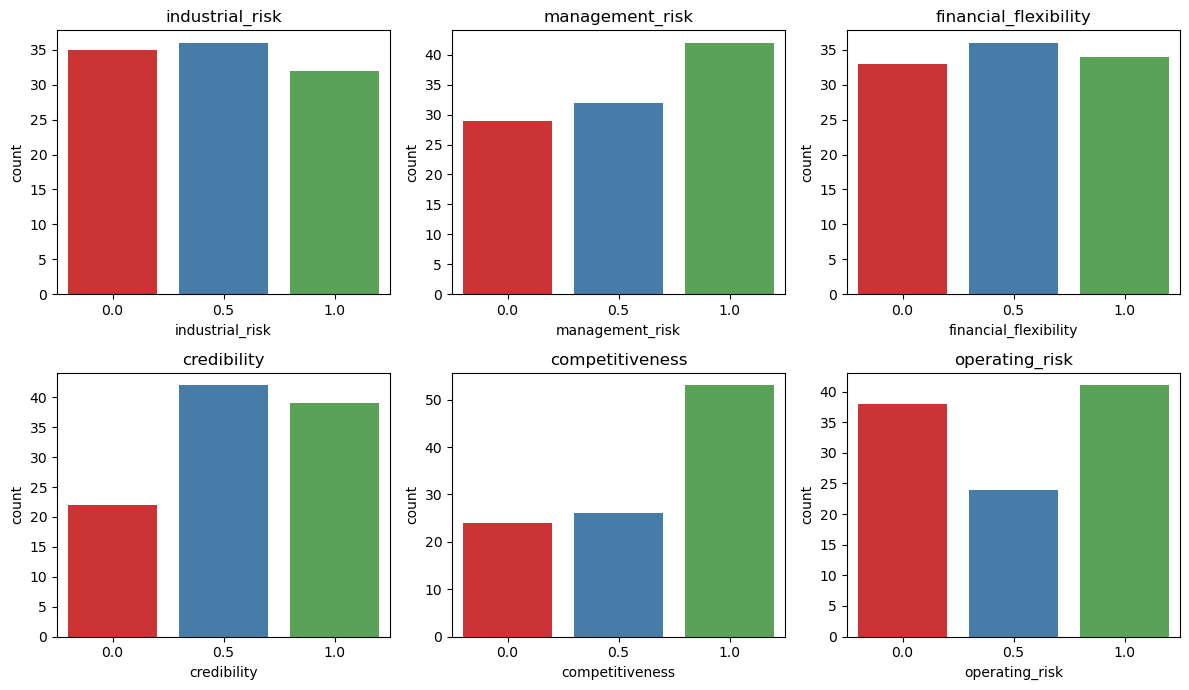

In [67]:
fig, axes = plt.subplots(2, 3, figsize=(12,7))
for i, col in enumerate(features):
    sns.countplot(data=df, x=col,palette='Set1',ax=axes.flat[i])
    axes.flat[i].set_title(col)
plt.tight_layout()
plt.show()

* Industrial risk is fairly balanced across categories, with a slightly higher count in the medium-risk category, while credibility has higher counts in the medium and high categories.
* Management risk has a higher count in the high-risk category, while operating risk has higher counts in both the low- and high-risk categories.
* Financial flexibility is fairly balanced across categories, with a slight concentration in the medium category.
* Competitiveness has a higher count in the high category, while the low and medium categories have fewer observations.

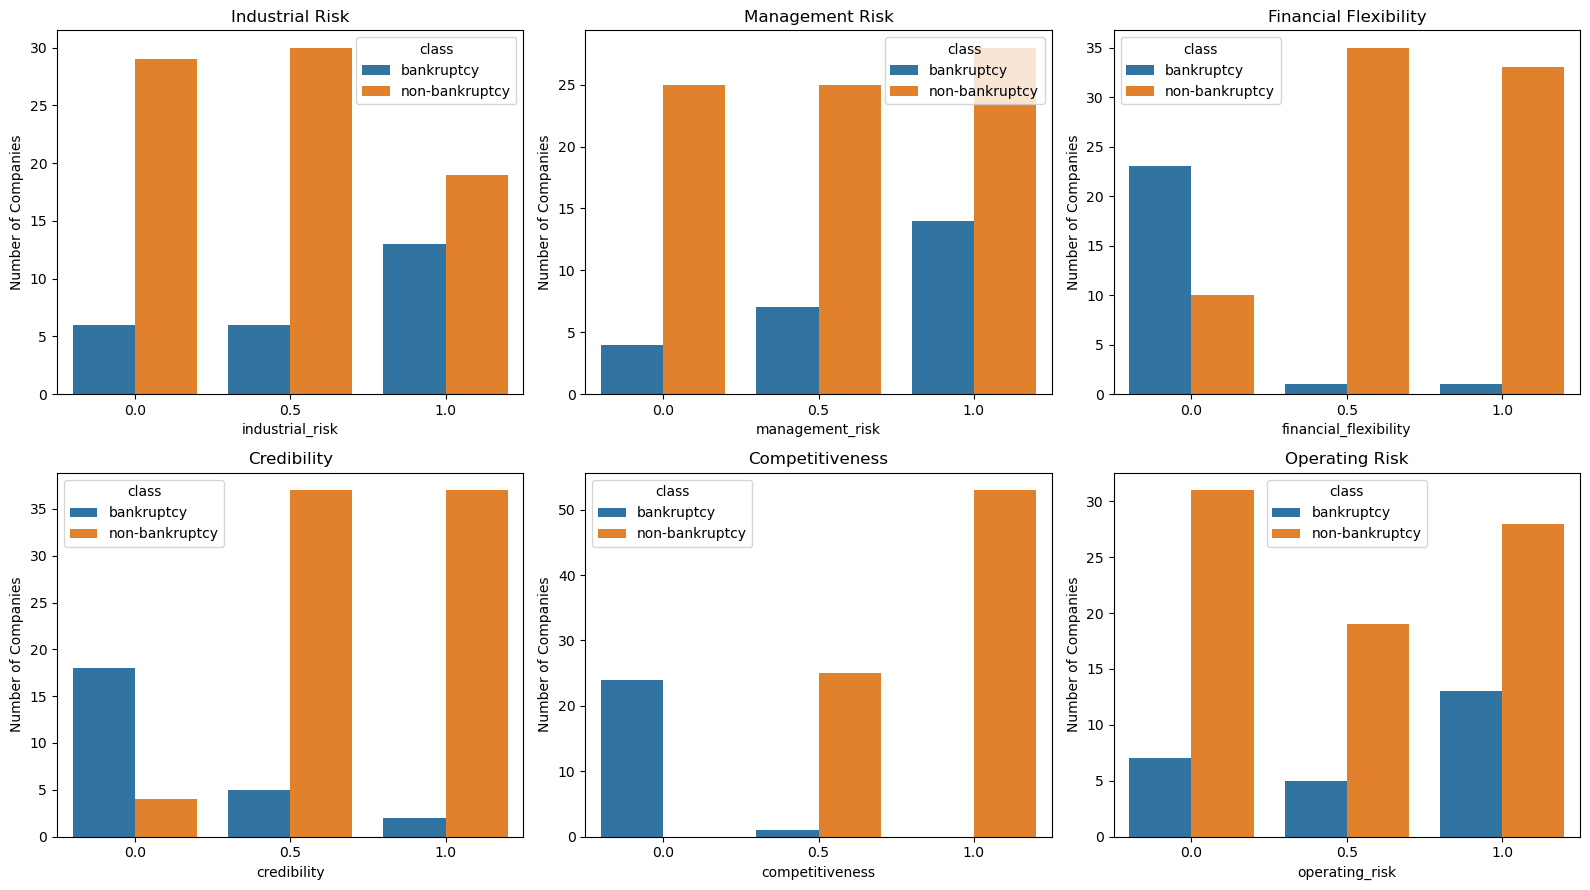

In [68]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for i, col in enumerate(features):
    sns.countplot(data=df, x=col, hue="class", ax=axes[i])
    axes[i].set_title(col.replace("_", " ").title())
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Number of Companies")

plt.tight_layout()
plt.show()

Barplot analysis

* Industrial Risk: High industrial risk is more common among bankrupt companies, although overlap between both classes suggests that this feature alone may not reliably predict bankruptcy.
* Management Risk: High management risk is more frequently observed among bankrupt companies, while lower risk levels are more common among non-bankrupt companies.
* Financial Flexibility: Bankrupt companies are concentrated mainly at 0, indicating low financial flexibility. Non-bankrupt companies are more common at 0.5 and 1.
* Credibility: Low credibility is predominantly associated with bankrupt companies, whereas medium and high credibility are more common among non-bankrupt companies.
* Competitiveness: Low competitiveness is strongly associated with bankruptcy in this dataset, while medium and high competitiveness are predominantly observed among non-bankrupt companies.
* Operating Risk: High operating risk is more common among bankrupt companies, whereas low operating risk is more common among non-bankrupt companies, although some overlap exists between the classes.

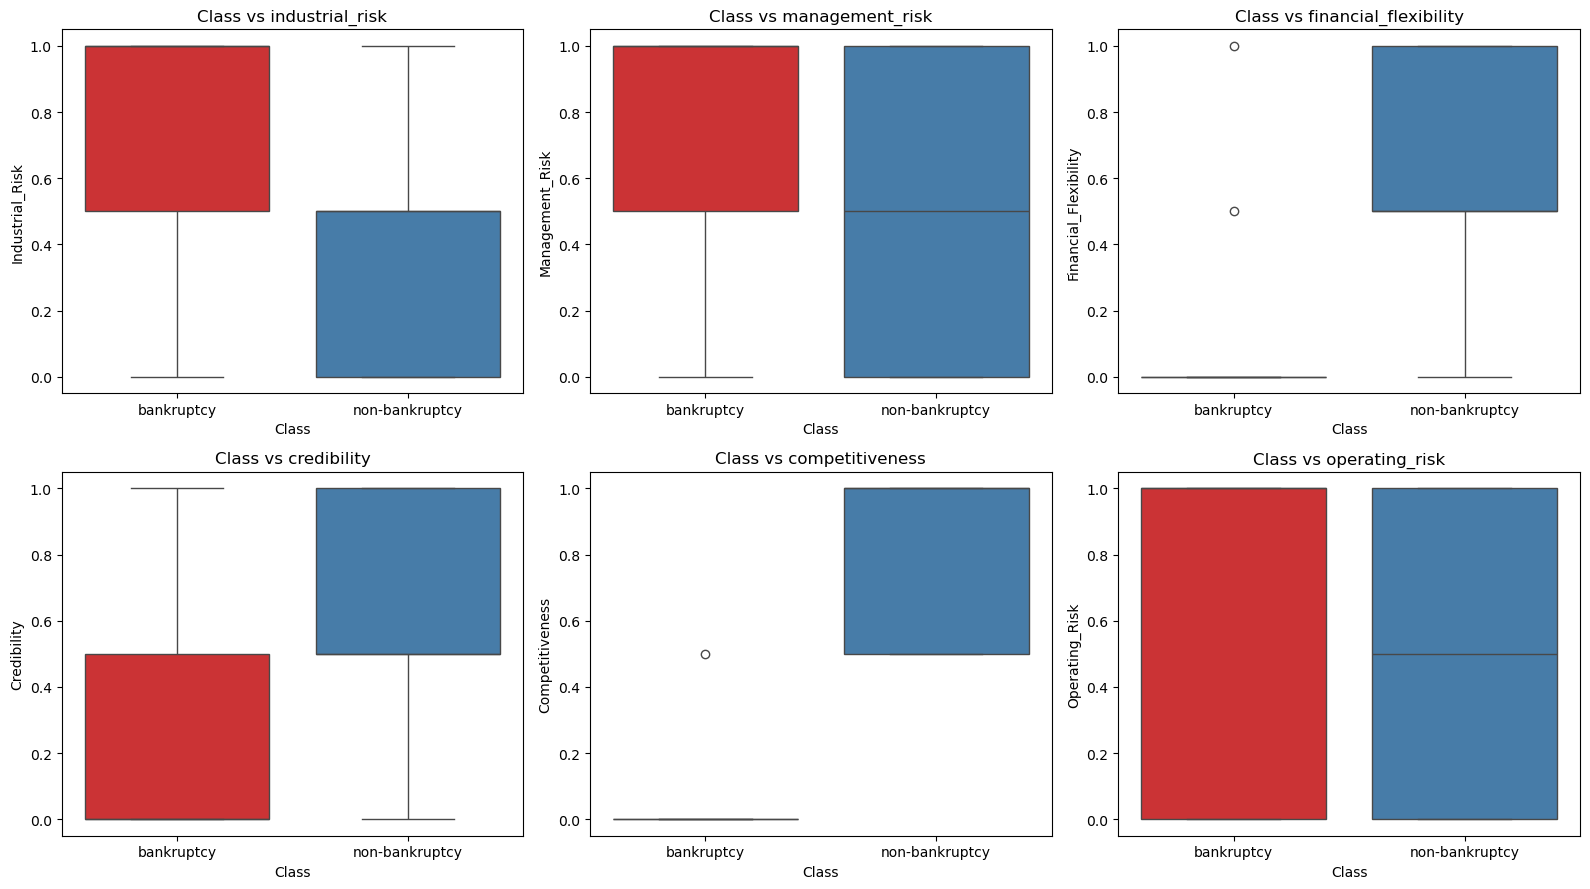

In [69]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for i, col in enumerate(features):
    sns.boxplot(x="class",y=col,data=df,hue="class",palette="Set1",legend=False,ax=axes[i])
    axes[i].set_title(f"Class vs {col}")
    axes[i].set_xlabel("Class")
    axes[i].set_ylabel(col.title())
    axes[i].grid(False)

plt.tight_layout()
plt.show()

Boxplot Analysis

* Industrial Risk: Bankrupt companies tend to have higher industrial risk.
* Management Risk: Bankrupt companies generally show higher management risk.
* Financial Flexibility: Bankrupt companies tend to have lower financial flexibility.
* Credibility: Bankrupt companies generally show lower credibility.
* Competitiveness: Bankrupt companies tend to have lower competitiveness.
* Operating Risk: Bankrupt companies generally show higher operating risk.

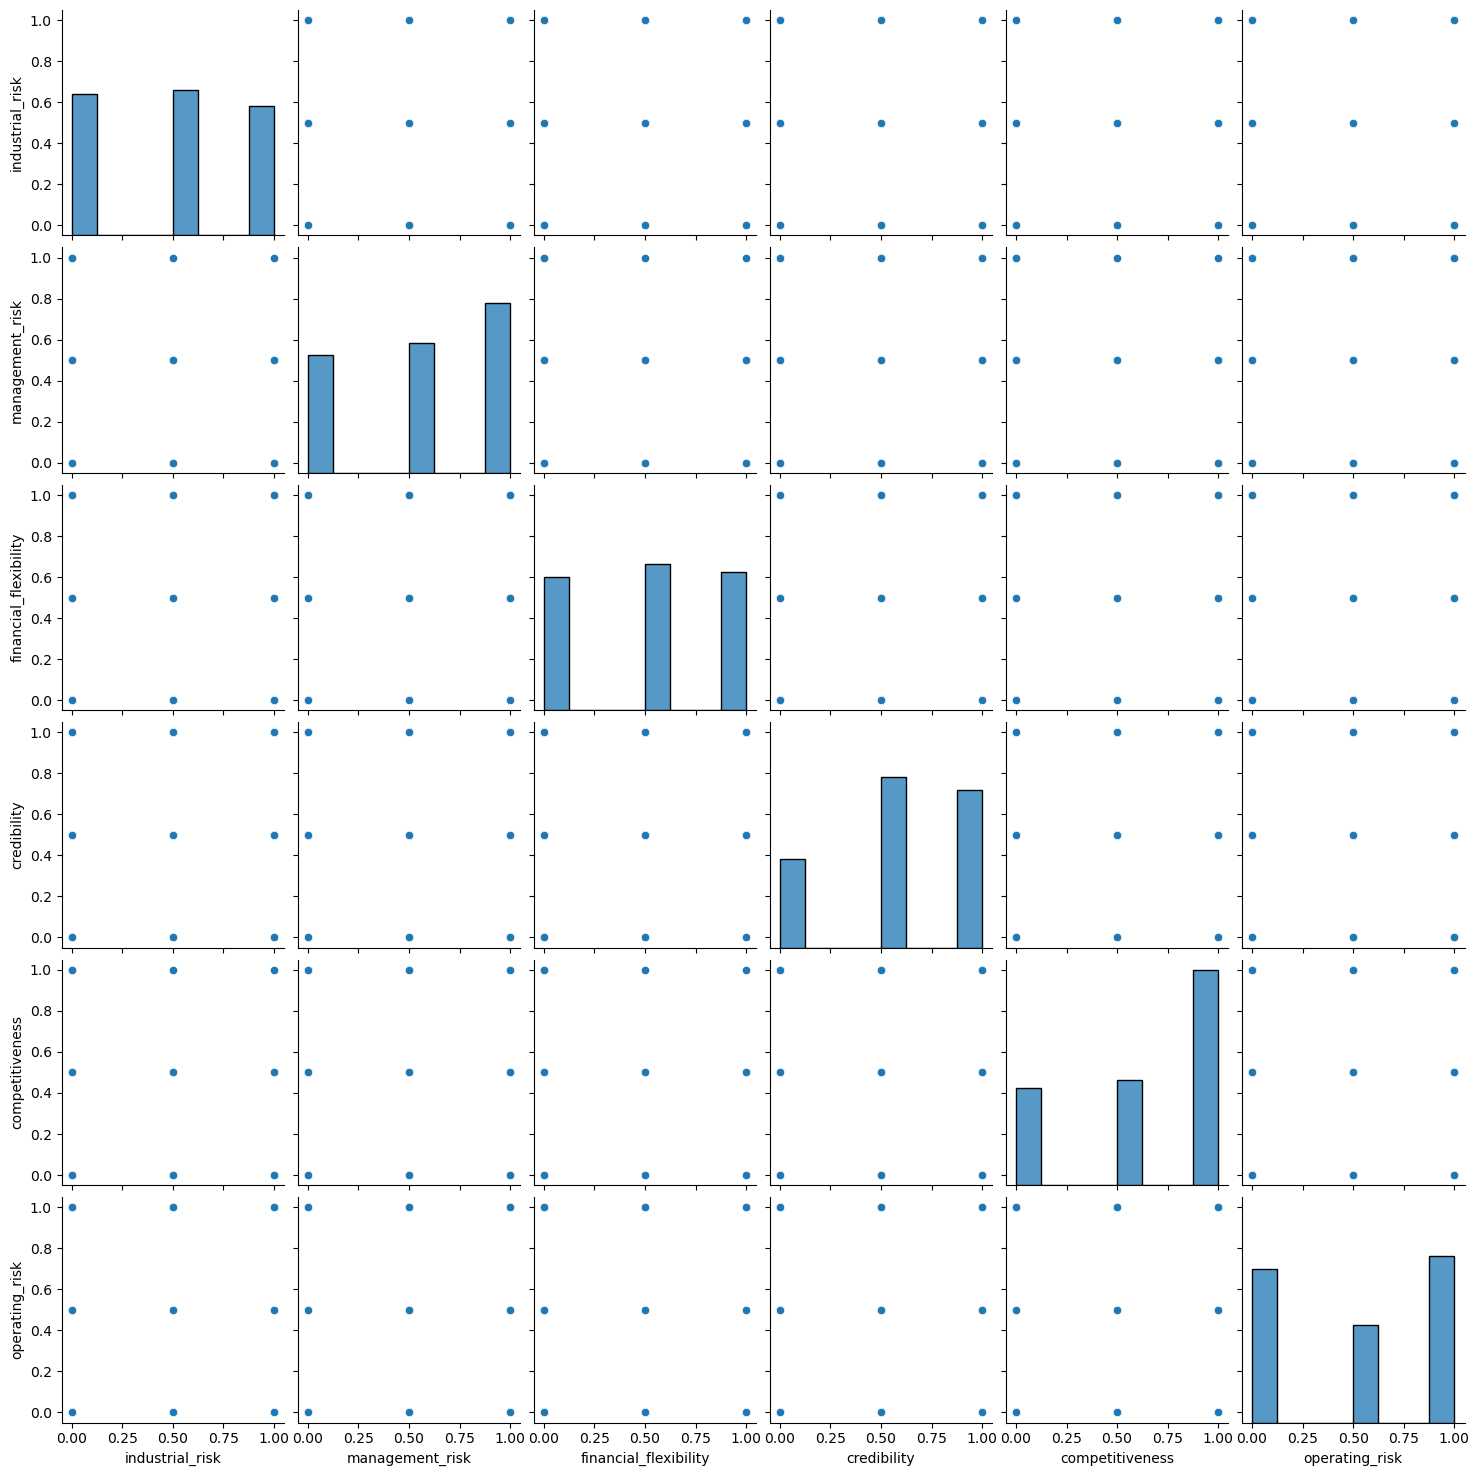

In [70]:
sns.pairplot(df)

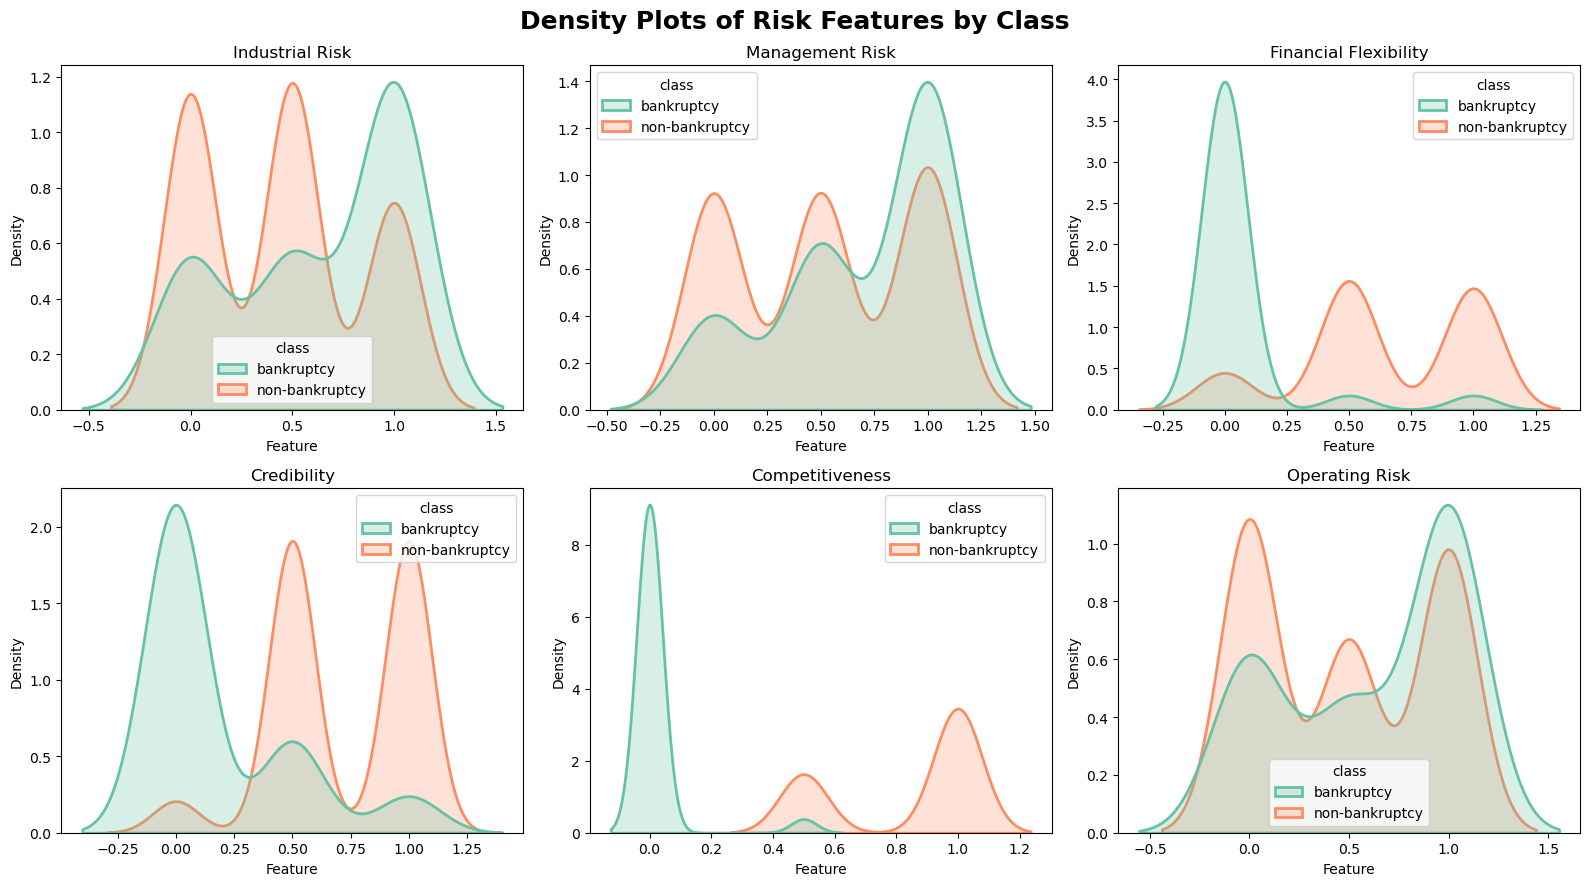

In [71]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()
palette = {'bankruptcy': '#3182bd','non-bankruptcy': '#e6550d'}
for i, col in enumerate(features):
    sns.kdeplot(data=df,x=col,hue='class',fill=True,common_norm=False,palette="Set2",linewidth=2,bw_adjust=0.8,ax=axes[i])
    axes[i].set_title(f'{col.replace("_", " ").title()}')
    axes[i].set_xlabel('Feature')
    axes[i].set_ylabel('Density')

fig.suptitle('Density Plots of Risk Features by Class',
             fontsize=18, fontweight='bold')

plt.tight_layout()
plt.show()

In [72]:
df_new=df.copy()
df_new["class"] = df_new["class"].map({"bankruptcy": 1,"non-bankruptcy": 0})

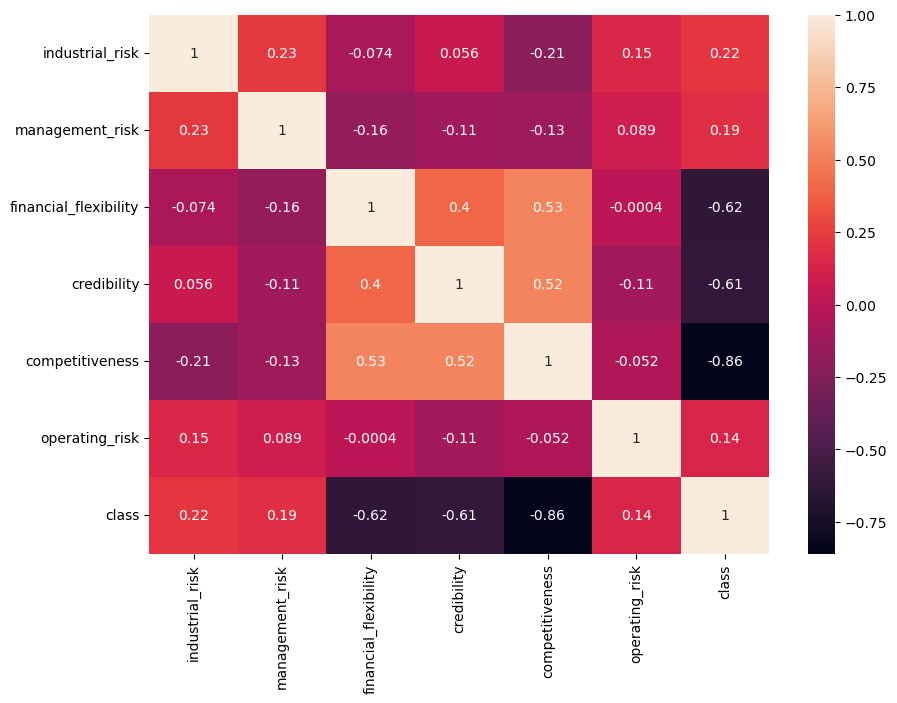

In [73]:
plt.figure(figsize=(10,7))
sns.heatmap(df_new.corr(),annot=True)
plt.show()

* Competitiveness has a strong negative correlation with the bankruptcy class, indicating that higher competitiveness is generally associated with a lower likelihood of bankruptcy.
* Financial flexibility and credibility also have strong negative correlations with the bankruptcy class, suggesting that better financial flexibility and credibility are associated with non-bankruptcy.
* Competitiveness and credibility are positively correlated with financial flexibility, indicating that companies with better financial flexibility tend to have higher competitiveness and credibility.
* Credibility and competitiveness are also positively correlated, showing that these factors tend to increase together.
* Management risk, operating risk, and industrial risk show weak to moderate positive correlations with bankruptcy, indicating that higher risk levels are associated with a greater likelihood of bankruptcy, but their relationships are weaker compared with the other features.

### Overall EDA Insights

* The EDA suggests that financial flexibility, credibility, and competitiveness show the clearest differences between bankrupt and non-bankrupt companies.
* The dataset contains 250 records, with 57.2% non-bankruptcy and 42.8% bankruptcy cases.
* Bankrupt companies generally show higher industrial, management, and operating risks, along with lower financial flexibility, credibility, and competitiveness.
* Competitiveness has the strongest negative correlation with bankruptcy, followed by credibility and financial flexibility.
* Management, operating, and industrial risks show weaker positive correlations with bankruptcy.
* Competitiveness, credibility, and financial flexibility are positively correlated with each other.

## Part2 - Model Building & Evaluation

### Data Preprocessing

In [74]:
LE = LabelEncoder()
df["class"] = LE.fit_transform(df["class"])
df.head()

,industrial_risk,management_risk,financial_flexibility,credibility,competitiveness,operating_risk,class
0,0.5,1.0,0.0,0.0,0.0,0.5,0
1,0.0,1.0,0.0,0.0,0.0,1.0,0
2,1.0,0.0,0.0,0.0,0.0,1.0,0
3,0.5,0.0,0.0,0.5,0.0,1.0,0
4,1.0,1.0,0.0,0.0,0.0,1.0,0


In [75]:
df["class"].value_counts()

class
1    78
0    25
Name: count, dtype: int64

In [76]:
X = df.drop('class',axis=1)
y = df["class"]

In [77]:
X_train,X_test,y_train,y_test = train_test_split(X,y, test_size = 0.3,random_state=42,stratify=y)

In [78]:
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

Training records: 72
Testing records: 31

Training class distribution:
class
1    55
0    17
Name: count, dtype: int64

Testing class distribution:
class
1    23
0     8
Name: count, dtype: int64


In [79]:
LR_model = LogisticRegression(max_iter=1000, random_state=42)
LR_model.fit(X_train, y_train)
y_pred_lr = LR_model.predict(X_test)

In [80]:
accuracy = accuracy_score(y_test,y_pred_lr)
print("Accuracy:", accuracy)

Accuracy: 0.967741935483871


In [81]:
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_lr))
print("\nClassification_repor:")
print(classification_report(y_test,y_pred_lr))


Confusion Matrix:
[[ 7  1]
 [ 0 23]]

Classification_repor:
              precision    recall  f1-score   support

           0       1.00      0.88      0.93         8
           1       0.96      1.00      0.98        23

    accuracy                           0.97        31
   macro avg       0.98      0.94      0.96        31
weighted avg       0.97      0.97      0.97        31



In [82]:
coef = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': LR_model.coef_[0]
})
coef.sort_values(by='Coefficient', ascending=False)

,Feature,Coefficient
4,competitiveness,2.624620
2,financial_flexibility,1.974200
3,credibility,1.131843
5,operating_risk,-0.293434
1,management_risk,-0.432559
0,industrial_risk,-0.477650


In [83]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scores = cross_val_score(
    LR_model, X_train, y_train,
    cv=cv,
    scoring='accuracy'
)

print("Fold accuracies:", scores)
print("Mean accuracy:", scores.mean())
print("Standard deviation:", scores.std())

Fold accuracies: [0.93333333 0.93333333 1.         1.         1.        ]
Mean accuracy: 0.9733333333333334
Standard deviation: 0.03265986323710904


## DESICION TREE

In [84]:
DT_model = DecisionTreeClassifier()
DT_model.fit(X_train, y_train)

DecisionTreeClassifier()

In [85]:
print(DT_model.score(X_train, y_train))
print(DT_model.score(X_test, y_test))

1.0
1.0


In [86]:
y_pred_dt=DT_model.predict(X_test)

In [87]:
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_dt))
print("\nClassification_repor:")
print(classification_report(y_test,y_pred_dt))


Confusion Matrix:
[[ 8  0]
 [ 0 23]]

Classification_repor:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         8
           1       1.00      1.00      1.00        23

    accuracy                           1.00        31
   macro avg       1.00      1.00      1.00        31
weighted avg       1.00      1.00      1.00        31



## DECISION TREE - Using GridsearchCV

In [88]:
DT_model2 = DecisionTreeClassifier()
params = [{
    "criterion":['gini','entropy','log_loss'],
    "max_depth":[1,2,3,4,5,6,7,8,9,10,11],
    "min_samples_split":[2,4,6,8],
    "min_samples_leaf": [1, 2,3,4, 5],
    "class_weight": [None, "balanced"]
}]

grid = GridSearchCV(DT_model2,param_grid=params)
grid.fit(X_train,y_train)

GridSearchCV(estimator=DecisionTreeClassifier(),
             param_grid=[{'class_weight': [None, 'balanced'],
                          'criterion': ['gini', 'entropy', 'log_loss'],
                          'max_depth': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11],
                          'min_samples_leaf': [1, 2, 3, 4, 5],
                          'min_samples_split': [2, 4, 6, 8]}])

In [89]:
print(grid.best_score_)
print(grid.best_params_)

0.9857142857142858
{'class_weight': None, 'criterion': 'gini', 'max_depth': 1, 'min_samples_leaf': 1, 'min_samples_split': 2}


In [90]:
DT_model3= DecisionTreeClassifier(criterion="gini",max_depth=1,min_samples_split=2,min_samples_leaf=1,random_state=42)
DT_model3.fit(X_train, y_train)

DecisionTreeClassifier(max_depth=1, random_state=42)

In [91]:
print(DT_model3.score(X_train, y_train))
print(DT_model3.score(X_test, y_test))

0.9861111111111112
1.0


In [92]:
y_pred_dt2=DT_model3.predict(X_test)

In [93]:
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_dt2))
print("\nClassification_repor:")
print(classification_report(y_test,y_pred_dt2))


Confusion Matrix:
[[ 8  0]
 [ 0 23]]

Classification_repor:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         8
           1       1.00      1.00      1.00        23

    accuracy                           1.00        31
   macro avg       1.00      1.00      1.00        31
weighted avg       1.00      1.00      1.00        31



In [94]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scores = cross_val_score(
    DT_model, X_train, y_train,
    cv=cv,
    scoring='accuracy')

print("Fold accuracies:", scores)
print("Mean accuracy:", scores.mean())
print("Standard deviation:", scores.std())

Fold accuracies: [0.93333333 0.93333333 0.92857143 0.92857143 1.        ]
Mean accuracy: 0.9447619047619048
Standard deviation: 0.027701027756664727


## Random Forest

In [95]:
RF_model = RandomForestClassifier(n_estimators=100,random_state=42)
RF_model.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

In [96]:
y_pred_rf = RF_model.predict(X_test)

print("Train Accuracy:", RF_model.score(X_train, y_train))
print("Test Accuracy:", accuracy_score(y_test, y_pred_rf))

Train Accuracy: 1.0
Test Accuracy: 1.0


In [97]:
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))
print("\nClassification_repor:")
print(classification_report(y_test,y_pred_rf))


Confusion Matrix:
[[ 8  0]
 [ 0 23]]

Classification_repor:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         8
           1       1.00      1.00      1.00        23

    accuracy                           1.00        31
   macro avg       1.00      1.00      1.00        31
weighted avg       1.00      1.00      1.00        31



In [98]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scores = cross_val_score(
    LR_model, X_train, y_train,
    cv=cv,
    scoring='accuracy'
)

print("Fold accuracies:", scores)
print("Mean accuracy:", scores.mean())
print("Standard deviation:", scores.std())

Fold accuracies: [0.93333333 0.93333333 1.         1.         1.        ]
Mean accuracy: 0.9733333333333334
Standard deviation: 0.03265986323710904


## SVM

In [99]:
SVM_model = SVC()
SVM_model.fit(X_train,y_train)

SVC()

In [100]:
y_pred_svm= SVM_model.predict(X_test)

In [101]:
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_svm))
print("\nClassification_repor:")
print(classification_report(y_test,y_pred_svm))


Confusion Matrix:
[[ 7  1]
 [ 0 23]]

Classification_repor:
              precision    recall  f1-score   support

           0       1.00      0.88      0.93         8
           1       0.96      1.00      0.98        23

    accuracy                           0.97        31
   macro avg       0.98      0.94      0.96        31
weighted avg       0.97      0.97      0.97        31



In [102]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scores = cross_val_score(
   SVM_model, X_train, y_train,
    cv=cv,
    scoring='accuracy'
)

print("Fold accuracies:", scores)
print("Mean accuracy:", scores.mean())
print("Standard deviation:", scores.std())

Fold accuracies: [0.93333333 1.         1.         1.         1.        ]
Mean accuracy: 0.9866666666666667
Standard deviation: 0.02666666666666666


## KNN

In [103]:
KNN = KNeighborsClassifier(n_neighbors=5)
KNN.fit(X_train,y_train)

KNeighborsClassifier()

In [104]:
y_pred_knn = KNN.predict(X_test)

In [105]:
print("Train Accuracy:", KNN.score(X_train, y_train))
print("Test Accuracy:", accuracy_score(y_test, y_pred_knn))

Train Accuracy: 1.0
Test Accuracy: 0.967741935483871


In [106]:
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_knn))
print("\nClassification_repor:")
print(classification_report(y_test,y_pred_knn))


Confusion Matrix:
[[ 7  1]
 [ 0 23]]

Classification_repor:
              precision    recall  f1-score   support

           0       1.00      0.88      0.93         8
           1       0.96      1.00      0.98        23

    accuracy                           0.97        31
   macro avg       0.98      0.94      0.96        31
weighted avg       0.97      0.97      0.97        31



In [107]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scores = cross_val_score(
    KNN, X_train, y_train,
    cv=cv,
    scoring='accuracy'
)

print("Fold accuracies:", scores)
print("Mean accuracy:", scores.mean())
print("Standard deviation:", scores.std())

Fold accuracies: [1.         0.93333333 1.         0.92857143 1.        ]
Mean accuracy: 0.9723809523809525
Standard deviation: 0.03385978825644032


## Naive Bayes

In [108]:
NB_model = GaussianNB()
NB_model.fit(X_train, y_train)

GaussianNB()

In [109]:
y_pred_nb = NB_model.predict(X_test)

In [110]:
print("Train Accuracy:", NB_model.score(X_train, y_train))
print("Test Accuracy:", accuracy_score(y_test, y_pred_nb))

Train Accuracy: 0.9861111111111112
Test Accuracy: 0.9354838709677419


In [111]:
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_nb))
print("\nClassification_repor:")
print(classification_report(y_test,y_pred_nb))


Confusion Matrix:
[[ 6  2]
 [ 0 23]]

Classification_repor:
              precision    recall  f1-score   support

           0       1.00      0.75      0.86         8
           1       0.92      1.00      0.96        23

    accuracy                           0.94        31
   macro avg       0.96      0.88      0.91        31
weighted avg       0.94      0.94      0.93        31



In [112]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scores = cross_val_score(
    NB_model, X_train, y_train,
    cv=cv,
    scoring='accuracy'
)

print("Fold accuracies:", scores)
print("Mean accuracy:", scores.mean())
print("Standard deviation:", scores.std())

Fold accuracies: [0.93333333 1.         1.         1.         0.92857143]
Mean accuracy: 0.9723809523809525
Standard deviation: 0.03385978825644033


## XGBOOST

In [113]:
xgb_model= XGBClassifier(objective='binary:logistic', random_state=42)
xgb_model.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=None, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=None,
              n_jobs=None, num_parallel_tree=None, ...)

In [114]:
y_pred_train_xgb = xgb_model.predict(X_train)
y_pred_xgb= xgb_model.predict(X_test)

In [115]:
accuracy_tr= accuracy_score(y_train, y_pred_train_xgb)
accuracy_xgb = accuracy_score(y_test, y_pred_xgb)
print("XGBoost - Training Accuracy:", accuracy_tr)
print("XGBoost - Test Accuracy:", accuracy_xgb)

XGBoost - Training Accuracy: 0.9861111111111112
XGBoost - Test Accuracy: 1.0


In [116]:
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_xgb))
print("\nClassification_repor:")
print(classification_report(y_test,y_pred_xgb))


Confusion Matrix:
[[ 8  0]
 [ 0 23]]

Classification_repor:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         8
           1       1.00      1.00      1.00        23

    accuracy                           1.00        31
   macro avg       1.00      1.00      1.00        31
weighted avg       1.00      1.00      1.00        31



## Comparison

In [117]:
predictions = {
    "Logistic Regression": y_pred_lr,
    "Decision Tree": y_pred_dt,
    "Random Forest": y_pred_rf,
    "SVM": y_pred_svm,
    "KNN": y_pred_knn,
    "Naive Bayes": y_pred_nb,
    "XGBoost": y_pred_xgb
}

models = {
    "Logistic Regression": LR_model,
    "Decision Tree": DT_model,
    "Random Forest": RF_model,
    "SVM": SVM_model,
    "KNN": KNN,
    "Naive Bayes": NB_model,
    "XGBoost": xgb_model
}

cv = StratifiedKFold(
    n_splits=5, shuffle=True, random_state=42
)

results = []

for name, y_pred in predictions.items():

    # Test-set metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)

    # Cross-validation scores
    scores = cross_val_score(
        models[name], X_train, y_train,
        cv=cv, scoring="accuracy"
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1,
        "Mean 5-Fold CV Accuracy": scores.mean(),
        "CV Std. Dev.": scores.std()
    })

comparison_df = pd.DataFrame(results)

display(comparison_df.round(3))

,Model,Accuracy,Precision,Recall,F1-Score,Mean 5-Fold CV Accuracy,CV Std. Dev.
0,Logistic Regression,0.968,0.958,1.0,0.979,0.973,0.033
1,Decision Tree,1.000,1.000,1.0,1.000,0.945,0.028
2,Random Forest,1.000,1.000,1.0,1.000,0.987,0.027
3,SVM,0.968,0.958,1.0,0.979,0.987,0.027
4,KNN,0.968,0.958,1.0,0.979,0.972,0.034
5,Naive Bayes,0.935,0.920,1.0,0.958,0.972,0.034
6,XGBoost,1.000,1.000,1.0,1.000,0.973,0.033


#### Best Model: Random Forest

Based on your comparison table, Random Forest is the best-performing model because it achieved 100% test accuracy, precision, recall, and F1-score, along with a mean 5-fold cross-validation accuracy of 98.7% and a standard deviation of 0.027.

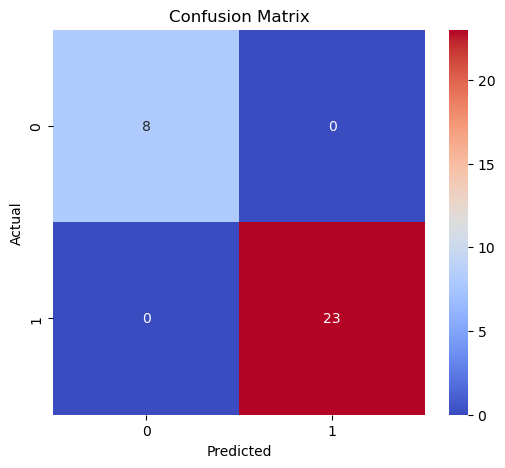

In [118]:
cm = confusion_matrix(y_test, y_pred_rf)
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True,cmap='coolwarm')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

* True Negatives (TN): All 8 actual bankruptcy cases were correctly classified as Class 0.
* True Positives (TP): All 23 actual non-bankruptcy cases were correctly classified as Class 1.
* False Positives (FP): No bankruptcy cases were incorrectly predicted as non-bankruptcy.
* False Negatives (FN): No non-bankruptcy cases were incorrectly predicted as bankruptcy.
* Accuracy: 100% - all 31 test observations were correctly classified.

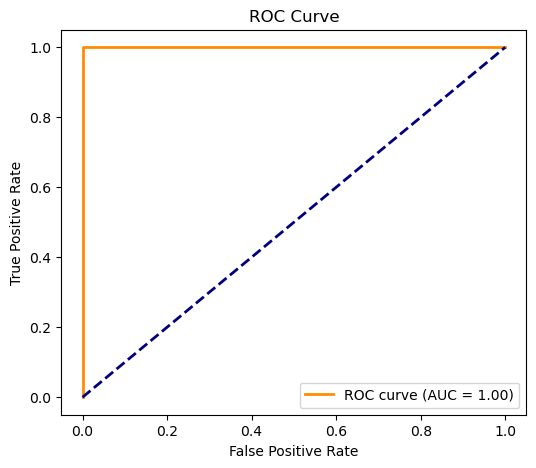

AUC Score: 1.0


In [119]:
RF_model.predict_proba(X)[:,1]
y_pred_proba = RF_model.predict_proba(X_test)[:, 1]

# ROC Curve and AUC
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, color='darkorange', lw=2,
         label='ROC curve (AUC = %0.2f)' % roc_auc)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc='lower right')
plt.show()

print("AUC Score:", roc_auc)

## Insights

* Random Forest: Best overall performance, achieving 100% test accuracy, precision, recall, and F1-score, with a high mean 5-fold cross-validation accuracy of 98.7% and low variability
* SVM: Strong alternative, achieving 96.8% test accuracy and 98.7% mean cross-validation accuracy, with consistent performance across folds.
* Decision Tree: Achieved perfect test-set metrics (100%) but its mean cross-validation accuracy was lower at 94.5%, indicating less consistent generalization.
* XGBoost: Achieved 100% test accuracy, precision, recall, and F1-score, with a mean cross-validation accuracy of 97.3%.
* Logistic Regression: Achieved 96.8% test accuracy and 97.3% mean cross-validation accuracy, while maintaining 100% recall.
* KNN: Achieved 96.8% test accuracy and 97.2% mean cross-validation accuracy, with 100% recall.
* Naive Bayes: Achieved 93.5% test accuracy and 97.2% mean cross-validation accuracy. Although recall was 100%, its overall test performance was the lowest among the evaluated models.
*Random Forest demonstrated the strongest balance of test-set performance and cross-validation consistency. It was therefore selected as the leading model for identifying companies at risk of bankruptcy and supporting further financial assessment.